**Name:- Pranali Sagar Kamble**

**Roll No:- 55**

# Understanding Any Dataset Like a Data Scientist
## A Complete Guide to Exploratory Data Analysis (EDA) using Python

Welcome! This notebook is a **complete, hands-on course on EDA** — the very first and most
important skill of every Data Scientist / ML / DL engineer.Prepared by Dr. Sachin Balawant Takmare.

By the end of this notebook you will be able to open **any dataset you have never seen before**
and confidently answer:

- What does this data look like?
- Is it clean or messy?
- What patterns, trends, and relationships does it hide?
- Is it ready for Machine Learning?

**Who is this for?** Engineering students, beginners in Data Science / ML / DL, and anyone who
wants a rock-solid EDA foundation.

**Datasets used in this notebook**

| Dataset | Why we use it |
|---|---|
|  Titanic | Missing values, categorical data, cleaning, encoding |
|  Iris | Pure numerical analysis, pair plots, classification |
|  Tips | GroupBy, statistics, visualization |
|  Penguins | Missing values + mixed data types |
|  California Housing | Scaling & correlation on larger numerical data |

>

##  Table of Contents

0. Introduction to Data & Datasets
1. The Data Science Workflow
2. Import Libraries
3. Loading Datasets
4. First Look at a Dataset
5. Understanding Variable Types
6. Dataset Summary
7. Statistical Concepts
8. Missing Values
9. Duplicate Values
10. Unique Values
11. Correlation
12. Outliers
13. Feature Scaling
14. Encoding Categorical Data
15. Data Visualization (the big one!)
16. GroupBy & Aggregation
17. Full Data Cleaning Project (Titanic)
18. Mini Guided EDA Project (Tips)
19. Professional EDA Checklist
20. Practice Questions (MCQ)
21. Programming Exercises
22. Mini Assignment (Penguins)
23. Interview Questions
24. Final Summary / Cheat Sheet

---
#  Introduction: What is Data & What is a Dataset?

**Data** is any raw fact or observation — a number, a word, an image, a sound.
On its own, a single piece of data doesn't tell you much (e.g. `21`).

A **Dataset** is an organized collection of data, usually arranged as a **table** of
**rows** and **columns**, where the data becomes meaningful.

### Rows vs Columns
- **Row** → one single *observation / record / sample* (e.g. one student).
- **Column** → one *variable / feature* measured for every row (e.g. `Age`).

### Feature vs Target
- **Features (X)** → the input columns used to make a prediction.
- **Target (y)** → the output column we want to predict (only exists in supervised ML).

### Numerical vs Categorical
- **Numerical** → measurable quantities (`Age`, `CGPA`, `Salary`).
- **Categorical** → labels / groups (`Gender`, `Placed`, `City`).

### Structured vs Unstructured Data
- **Structured** → fits neatly into rows & columns (Excel sheet, SQL table, CSV).
- **Unstructured** → no fixed format (images, audio, free text, video).

### Example: A Simple Student Dataset

In [ ]:
import pandas as pd

# A tiny hand-made dataset to illustrate the concepts above
student_data = {
    "RollNo": [1, 2, 3, 4, 5],
    "Name":   ["Vijay", "pooja", "Pranav", "Meera", "Shital"],
    "Age":    [19, 20, 19, 21, 20],
    "Gender": ["M", "F", "M", "F", "F"],
    "CGPA":   [8.4, 9.1, 7.8, 8.9, 7.2],
    "Placed": ["Yes", "Yes", "No", "Yes", "No"],
}

student_df = pd.DataFrame(student_data)
student_df   # displaying the DataFrame

,RollNo,Name,Age,Gender,CGPA,Placed
0,1,Vijay,19,M,8.4,Yes
1,2,pooja,20,F,9.1,Yes
2,3,Pranav,19,M,7.8,No
3,4,Meera,21,F,8.9,Yes
4,5,Shital,20,F,7.2,No


**Reading the table above:**
- Each **row** = one student → 5 rows = 5 students (samples).
- Each **column** = one variable measured for every student → 6 columns (features).
- `RollNo`, `Age`, `CGPA` → **Numerical** columns.
- `Name`, `Gender`, `Placed` → **Categorical** columns.
- If our goal is *"predict whether a student will be placed"*, then:
  - **Target (y)** = `Placed`
  - **Features (X)** = `Age`, `Gender`, `CGPA` (`RollNo`/`Name` are identifiers, not features)

>  **Common mistake:** Beginners often keep ID columns like `RollNo` or `Name` as
> features while training a model. IDs carry no real pattern and should almost always
> be dropped before modelling.

###  Quick Check
1. In the student dataset, is `Gender` numerical or categorical?
2. If we wanted to predict a student's `CGPA` instead, what would the target be now?

*(Think about it before scrolling further — answers follow the same logic explained above.)*

---
# 1. The Data Science Workflow

Every real-world Data Science / ML project follows roughly the same pipeline.
EDA (this whole notebook!) covers the **middle three stages** — and they usually
take up **70–80% of a data scientist's total project time**.

```
┌───────────────┐
│ Collect Data  │
└───────┬───────┘
        ▼
┌───────────────┐
│ Understand    │
│ Data          │   <── EDA
└───────┬───────┘        starts
        ▼                 here
┌───────────────┐
│ Clean Data    │
└───────┬───────┘        EDA
        ▼                 ends
┌───────────────┐        here
│ Visualize     │
│ Data          │
└───────┬───────┘
        ▼
┌───────────────┐
│ Feature       │
│ Engineering   │
└───────┬───────┘
        ▼
┌───────────────┐
│ Machine       │
│ Learning      │
└───────┬───────┘
        ▼
┌───────────────┐
│ Evaluation    │
└───────┬───────┘
        ▼
┌───────────────┐
│ Deployment    │
└───────────────┘
```

> **Best practice:** Never jump straight into building a model. A model trained on
> dirty, misunderstood data will always give unreliable results — **"Garbage in, garbage out."**

---
# 2️. Import Libraries

| Library | Why we need it |
|---|---|
| **NumPy** | Fast numerical computing; the foundation every other library is built on |
| **Pandas** | Loading, cleaning, and manipulating tabular data (DataFrames) |
| **Matplotlib** | The base plotting library — full control over every visual element |
| **Seaborn** | Beautiful statistical plots built on top of Matplotlib, works great with Pandas |
| **Scikit-learn** | Preprocessing tools (scaling, encoding) and ML algorithms |

In [ ]:
# Core libraries
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing (used later for scaling & encoding)
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, RobustScaler, Normalizer,
    LabelEncoder, OneHotEncoder, OrdinalEncoder
)

# Display / plotting settings
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


---
# 3️. Loading Datasets

We'll load **five** classic, beginner-friendly datasets. Each teaches a different EDA skill.

| Dataset | Load with | Best for |
|---|---|---|
| Titanic | `sns.load_dataset('titanic')` | Missing values, categorical data, full cleaning |
| Iris | `sns.load_dataset('iris')` | Pure numerical analysis, pairplots |
| Tips | `sns.load_dataset('tips')` | GroupBy, aggregation, visualization |
| Penguins | `sns.load_dataset('penguins')` | Missing values, mixed data types |
| California Housing | `sklearn.datasets.fetch_california_housing` | Scaling & correlation on larger numeric data |

**Titanic will be our main "storyline" dataset** — we'll keep coming back to it throughout
the notebook. The others appear where they best illustrate a concept.

In [ ]:
# Load all datasets we will use in this notebook
titanic  = sns.load_dataset("titanic")
iris     = sns.load_dataset("iris")
tips     = sns.load_dataset("tips")
penguins = sns.load_dataset("penguins")

print("Titanic :", titanic.shape)
print("Iris    :", iris.shape)
print("Tips    :", tips.shape)
print("Penguins:", penguins.shape)

Titanic : (891, 15)
Iris    : (150, 5)
Tips    : (244, 7)
Penguins: (344, 7)


In [ ]:
# California Housing — a larger, purely numerical dataset (fetched from scikit-learn)
from sklearn.datasets import fetch_california_housing

try:
    housing_bunch = fetch_california_housing(as_frame=True)
    housing = housing_bunch.frame
except Exception as e:
    # Fallback: if there is no internet access, build a similar synthetic dataset
    print("Could not download California Housing, generating a similar synthetic dataset instead.")
    from sklearn.datasets import make_regression
    X, y = make_regression(n_samples=2000, n_features=8, noise=15, random_state=42)
    cols = ["MedInc", "HouseAge", "AveRooms", "AveBedrms",
            "Population", "AveOccup", "Latitude", "Longitude"]
    housing = pd.DataFrame(X, columns=cols)
    housing["MedHouseVal"] = y

print("California Housing:", housing.shape)
housing.head()

California Housing: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Check Built-in Dataset from a library

In [ ]:
import seaborn as sns
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

**The dir() function lists all attributes, functions, classes, and datasets available in a module.**

In [ ]:
import plotly.express as px
dir(px.data)

['__all__',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__path__',
 '__spec__',
 'carshare',
 'election',
 'election_geojson',
 'experiment',
 'gapminder',
 'iris',
 'medals_long',
 'medals_wide',
 'stocks',
 'tips',
 'wind']

In [ ]:
import seaborn as sns
dir(sns)

['FacetGrid',
 'JointGrid',
 'PairGrid',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__path__',
 '__spec__',
 '__version__',
 '_base',
 '_compat',
 '_core',
 '_docstrings',
 '_orig_rc_params',
 '_statistics',
 '_stats',
 'algorithms',
 'axes_style',
 'axisgrid',
 'barplot',
 'blend_palette',
 'boxenplot',
 'boxplot',
 'categorical',
 'catplot',
 'choose_colorbrewer_palette',
 'choose_cubehelix_palette',
 'choose_dark_palette',
 'choose_diverging_palette',
 'choose_light_palette',
 'clustermap',
 'cm',
 'color_palette',
 'colors',
 'countplot',
 'crayon_palette',
 'crayons',
 'cubehelix_palette',
 'dark_palette',
 'desaturate',
 'despine',
 'displot',
 'distplot',
 'distributions',
 'diverging_palette',
 'dogplot',
 'ecdfplot',
 'external',
 'get_data_home',
 'get_dataset_names',
 'heatmap',
 'histplot',
 'hls_palette',
 'husl_palette',
 'jointplot',
 'kdeplot',
 'light_palette',
 'lineplot',
 'lmplot',
 'load_dataset',
 'matrix

---
# 4️. First Look at a Dataset

Before doing anything else, always run these commands on a new dataset (using **Titanic**).

In [ ]:
titanic.head() # first 5 rows — a quick peek at the data

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
titanic.tail() # last 5 rows — useful to check if data ends correctly (no junk rows)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [ ]:
titanic.sample() # any random 5 rows

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
264,0,3,female,NaN,0,0,7.75,Q,Third,woman,False,NaN,Queenstown,no,True


In [ ]:
print("Shape (rows, columns):", titanic.shape) # To show rows,colums
print("Size (total values)  :", titanic.size)  # to show Total no. of values(891*15=13365)
print("Dimensions (ndim)    :", titanic.ndim) # To show the dimensions

Shape (rows, columns): (891, 15)
Size (total values)  : 13365
Dimensions (ndim)    : 2


In [ ]:
print("Columns:\n", list(titanic.columns))
print("\nIndex:", titanic.index)

Columns:
 ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Index: RangeIndex(start=0, stop=891, step=1)


---
# 5️. Understanding Variable Types

```
                       Variable Types
                             │
            ┌────────────────┴────────────────┐
            ▼                                  ▼
       Numerical                          Categorical
            │                                  │
   ┌────────┴────────┐             ┌───────────┼───────────┐
   ▼                  ▼             ▼           ▼           ▼
Continuous        Discrete       Nominal     Ordinal      Binary
(can take any    (countable,   (no order:   (has order:  (only 2
 value, e.g.      e.g. no. of   e.g. City,   e.g. Grade   categories,
 Height, Fare)    siblings)     Gender)      A>B>C)       e.g. Yes/No)
```

| Type | Definition | Titanic Example |
|---|---|---|
| Continuous | Can take any value in a range | `fare`, `age` |
| Discrete | Countable whole numbers | `sibsp` (siblings/spouses), `parch` |
| Nominal | Categories with **no** order | `sex`, `embarked` |
| Ordinal | Categories **with** order | `pclass` (1st > 2nd > 3rd class) |
| Binary | Exactly two categories | `survived` (0/1), `alone` (True/False) |

>  **Tip:** Correctly identifying variable type decides *which plot* and *which
> preprocessing method* (scaling vs encoding) you'll use later in this notebook.

In [ ]:
# Let's classify Titanic's columns ourselves
titanic.dtypes

,0
survived,int64
pclass,int64
sex,object
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,object
class,category
who,object


**Interpretation:** Pandas infers types automatically:
- `int64` / `float64` → numerical columns (but `pclass`, `survived` are *technically*
  categorical even though stored as numbers!)
- `object` → text / categorical columns (`sex`, `embarked`, `who`, ...)
- `bool` → binary columns (`adult_male`, `alone`)
- `category` → `class`, `deck`, `embark_town` (pandas' special memory-efficient categorical type)

> **Common mistake:** Trusting `dtypes` blindly. A column of `0`s and `1`s (like
> `survived`) is stored as a number but is *conceptually categorical* — always think about
> the **meaning**, not just the storage type.

---
# 6️. Dataset Summary

In [ ]:
titanic.info() # 891-non null=missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


**Interpretation of `info()`:**
- Total rows (`RangeIndex`), total columns, and each column's **dtype**.
- **`Non-Null Count`** is the most important part — compare it to total rows (891) to spot
  missing data instantly. E.g. `age` has 714 non-null → **177 missing values**! `deck` has
  only 203 non-null → mostly missing.
- The `memory usage` line tells you how much RAM the DataFrame occupies.

In [ ]:
titanic.describe() #summary statistics for NUMERICAL columns only

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**Interpretation of `describe()`:**
- `count` → number of non-missing values.
- `mean`, `std` → average and spread of the data.
- `min`, `25%`, `50%` (median), `75%`, `max` → the **five-number summary** / quartiles.
- E.g. `fare`: mean ≈ 32, but max ≈ 512 — a huge gap, hinting at **outliers**.

In [ ]:
titanic.describe(include="all")   # summary for ALL columns (numeric + categorical)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Interpretation:** For categorical columns, Pandas now also shows:
- `unique` → number of distinct categories.
- `top` → the most frequent category.
- `freq` → how many times the top category appears.

E.g. `sex`: 2 unique values, top = `male`, freq = 577 → most passengers were male.

###  Quick Check
- Which column has the most missing values based on `info()`?
- What does the `75%` value in `describe()` represent?

---
# 7️. Statistical Concepts

Let's understand the numbers behind `describe()` using the `age` column.

```
        Min        Q1(25%)      Median(Q2)     Q3(75%)        Max
         |            |               |             |           |
  ───────┼────────────┼───────────────┼─────────────┼───────────┼──────►
         └────── IQR = Q3 − Q1 ────────┘
                (middle 50% of the data)
```

| Concept | Meaning | Formula / Note |
|---|---|---|
| **Mean** | Average value | sum of values ÷ count |
| **Median** | Middle value when sorted | robust to outliers |
| **Mode** | Most frequently occurring value | works for numeric & categorical |
| **Variance** | Average squared distance from the mean | spread of data |
| **Std. Deviation** | Square root of variance | spread, in original units |
| **Quartiles** | Values that split sorted data into 4 equal parts | Q1, Q2 (median), Q3 |
| **Percentile** | Value below which a given % of data falls | e.g. 90th percentile |
| **Range** | Max − Min | total spread |
| **IQR** | Q3 − Q1 | spread of the middle 50%, used for outlier detection |

---
# 8️. Missing Values

### How do missing values happen?
- A survey question left blank (e.g. someone didn't report their `age`).
- Sensor/equipment failure while recording data.
- Data lost during merging of multiple sources.
- Intentionally not applicable (e.g. `deck` unknown for many Titanic passengers).

In [ ]:
missing_count = titanic.isnull().sum()
missing_percent = (titanic.isnull().sum() / len(titanic) * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing %": missing_percent
}).sort_values("Missing %", ascending=False)

missing_summary[missing_summary["Missing Count"] > 0]

,Missing Count,Missing %
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


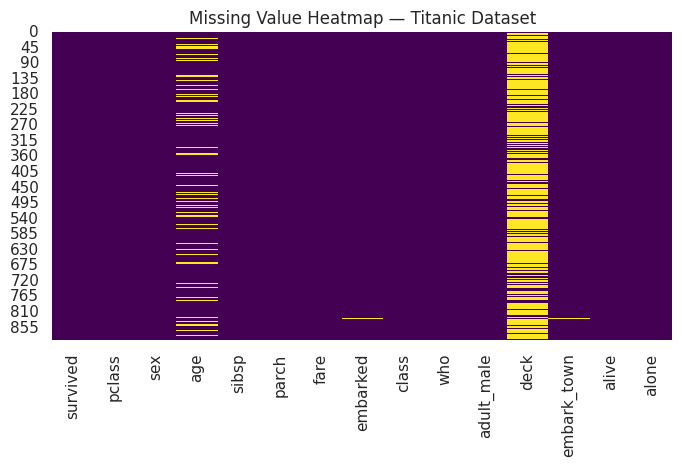

In [ ]:
# Visualization 1: Heatmap of missing values
plt.figure(figsize=(8, 4))
sns.heatmap(titanic.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Value Heatmap — Titanic Dataset")
plt.show()

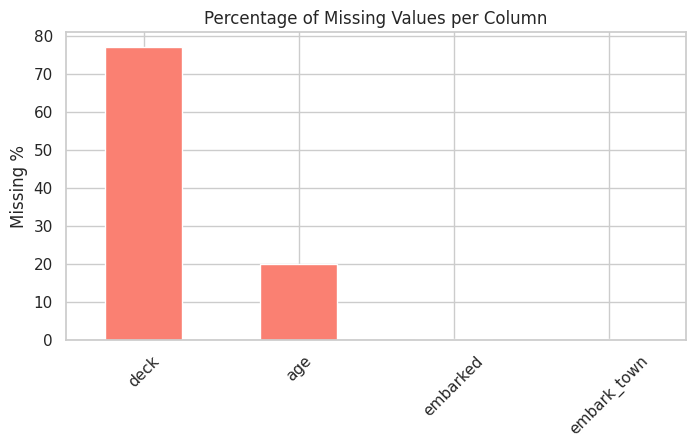

In [ ]:
# Visualization 2: Bar chart of missing value percentage
plt.figure(figsize=(8, 4))
missing_summary[missing_summary["Missing Count"] > 0]["Missing %"].plot(kind="bar", color="salmon")
plt.ylabel("Missing %")
plt.title("Percentage of Missing Values per Column")
plt.xticks(rotation=45)
plt.show()

**Interpretation:** `deck` (~77%) and `age` (~20%) have the most missing data;
`embarked`/`embark_town` are barely missing (~0.2%).

### Handling Missing Values — Methods

In [ ]:
df_demo = titanic.copy()   # always work on a COPY, never the original!

# 1. Drop rows with any missing value (use sparingly — can lose a lot of data)
df_drop = df_demo.dropna()
print("After dropna():", df_drop.shape)

# 2. Fill numerical column with MEAN
df_demo["age_mean_filled"] = df_demo["age"].fillna(df_demo["age"].mean())

# 3. Fill numerical column with MEDIAN (better when data is skewed / has outliers)
df_demo["age_median_filled"] = df_demo["age"].fillna(df_demo["age"].median())

# 4. Fill categorical column with MODE (most frequent value)
df_demo["embarked_mode_filled"] = df_demo["embarked"].fillna(df_demo["embarked"].mode()[0])

# 5. Forward Fill — carry the previous valid value forward
df_demo["age_ffill"] = df_demo["age"].ffill()

# 6. Backward Fill — carry the next valid value backward
df_demo["age_bfill"] = df_demo["age"].bfill()

# 7. Interpolation — estimate missing values using surrounding data
df_demo["age_interpolated"] = df_demo["age"].interpolate()

# 8. Fill with a CONSTANT value
df_demo["deck_constant_filled"] = df_demo["deck"].astype("object").fillna("Unknown")

df_demo[["age", "age_mean_filled", "age_median_filled",
         "age_ffill", "age_bfill", "age_interpolated"]].head(8)

After dropna(): (182, 15)


,age,age_mean_filled,age_median_filled,age_ffill,age_bfill,age_interpolated
0,22.0,22.000000,22.0,22.0,22.0,22.0
1,38.0,38.000000,38.0,38.0,38.0,38.0
2,26.0,26.000000,26.0,26.0,26.0,26.0
3,35.0,35.000000,35.0,35.0,35.0,35.0
4,35.0,35.000000,35.0,35.0,35.0,35.0
5,NaN,29.699118,28.0,35.0,54.0,44.5
6,54.0,54.000000,54.0,54.0,54.0,54.0
7,2.0,2.000000,2.0,2.0,2.0,2.0


**Which method should you use?**

| Method | Best when |
|---|---|
| Drop | Very few missing rows, or the column is mostly missing (like `deck`) |
| Mean | Numerical data, roughly symmetric, no big outliers |
| Median | Numerical data, skewed or has outliers |
| Mode | Categorical data |
| Forward/Backward Fill | Time-series / ordered data |
| Interpolation | Numerical, ordered data with a smooth trend |
| Constant (e.g. "Unknown") | When "missing" itself is meaningful information |

>  **Common mistake:** Filling missing values *before* splitting data into train/test sets
> using statistics from the **whole** dataset — this leaks test-set information into training
> (called *data leakage*). In real ML projects, always fit fillers (mean/median) on the
> training set only.



---
# 9️. Duplicate Values

Duplicate rows happen due to data entry errors, merging datasets twice, or scraping errors.

In [ ]:
print("Number of duplicate rows in Titanic:", titanic.duplicated().sum())

# Let's create an artificial example to see duplicates in action
demo = titanic.head(5).copy()
demo = pd.concat([demo, demo.iloc[[0, 2]]], ignore_index=True)  # manually duplicate 2 rows
print("\nDemo dataset shape (with duplicates):", demo.shape)
print("Duplicate rows found:", demo.duplicated().sum())

demo[demo.duplicated(keep=False)]   # show all copies of duplicated rows

Number of duplicate rows in Titanic: 107

Demo dataset shape (with duplicates): (7, 15)
Duplicate rows found: 2


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.250,S,Third,man,True,NaN,Southampton,no,False
2,1,3,female,26.0,0,0,7.925,S,Third,woman,False,NaN,Southampton,yes,True
5,0,3,male,22.0,1,0,7.250,S,Third,man,True,NaN,Southampton,no,False
6,1,3,female,26.0,0,0,7.925,S,Third,woman,False,NaN,Southampton,yes,True


In [ ]:
demo_cleaned = demo.drop_duplicates()
print("Shape before:", demo.shape, " | Shape after drop_duplicates():", demo_cleaned.shape)

Shape before: (7, 15)  | Shape after drop_duplicates(): (5, 15)


---
# 10. Unique Values

In [ ]:
print("Unique classes in 'pclass':", titanic["pclass"].unique())
print("Number of unique classes  :", titanic["pclass"].nunique())

print("\nValue counts for 'embarked':")
print(titanic["embarked"].value_counts())

print("\nValue counts (as %) for 'sex':")
print(titanic["sex"].value_counts(normalize=True).round(3) * 100)

Unique classes in 'pclass': [3 1 2]
Number of unique classes  : 3

Value counts for 'embarked':
embarked
S    644
C    168
Q     77
Name: count, dtype: int64

Value counts (as %) for 'sex':
sex
male      64.8
female    35.2
Name: proportion, dtype: float64


---
# 1️1️. Correlation

Correlation measures how strongly two numerical variables move together, from **-1 to +1**.

```
   -1                      0                      +1
    │                      │                       │
Strong Negative        No relation           Strong Positive
(as X↑, Y↓)                                   (as X↑, Y↑)
```

- **Positive correlation** → both variables increase together (e.g. `fare` & `pclass`
  reversed, since 1st class = expensive).
- **Negative correlation** → one increases as the other decreases.
- **Zero / near-zero correlation** → no linear relationship.

>  Correlation ≠ Causation! Two variables can correlate strongly without one causing the other.

In [ ]:
numeric_titanic = titanic.select_dtypes(include=np.number)
corr_matrix = numeric_titanic.corr()
corr_matrix

,survived,pclass,age,sibsp,parch,fare
survived,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
pclass,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
age,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
sibsp,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
parch,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
fare,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


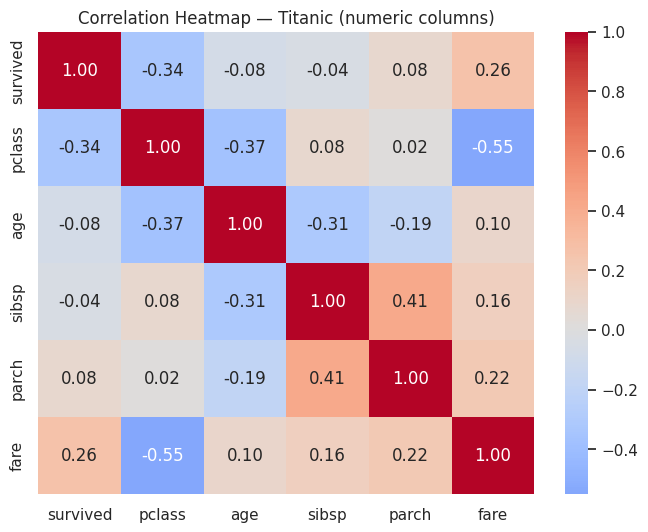

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — Titanic (numeric columns)")
plt.show()

---
# 1️2️. Outliers

**Outliers** are data points that differ drastically from the rest of the data.

**Real-world examples:** a `Salary` of ₹5,00,00,000 in a dataset of ₹3–10 lakh salaries;
a `Height` of 240 cm; a student `Marks` of 105 out of 100 (data-entry error);
an `Income` of ₹0 in a working adults dataset.

### Method 1 — Boxplot (visual)

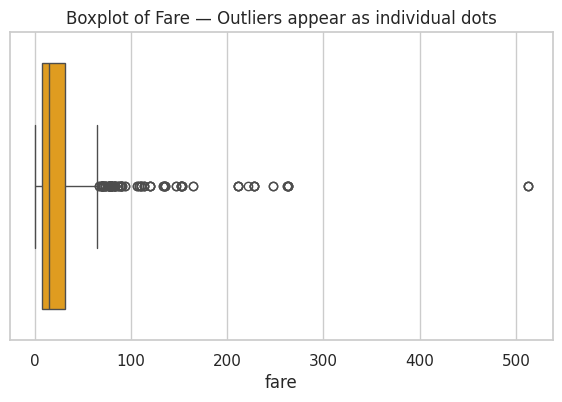

In [ ]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=titanic["fare"], color="orange")
plt.title("Boxplot of Fare — Outliers appear as individual dots")
plt.show()

### Method 2 — IQR Rule (mathematical)

In [ ]:
Q1 = titanic["fare"].quantile(0.25)
Q3 = titanic["fare"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = titanic[(titanic["fare"] < lower_bound) | (titanic["fare"] > upper_bound)]
print(f"Lower bound: {lower_bound:.2f}   Upper bound: {upper_bound:.2f}")
print("Number of outliers in 'fare':", outliers.shape[0])

Lower bound: -26.72   Upper bound: 65.63
Number of outliers in 'fare': 116


### Method 3 — Z-score (introduction)

In [ ]:
from scipy import stats

fare_no_na = titanic["fare"].dropna()
z_scores = np.abs(stats.zscore(fare_no_na))

z_outliers = fare_no_na[z_scores > 3]     # points more than 3 std-devs from the mean
print("Number of outliers using Z-score (|z| > 3):", z_outliers.shape[0])

Number of outliers using Z-score (|z| > 3): 20


**Interpretation:** A Z-score tells you *how many standard deviations* a point is from the
mean. `|z| > 3` is a common rule-of-thumb threshold for "extreme" values. Notice IQR and
Z-score can flag a slightly different number of outliers — they use different logic, so use
whichever suits your data's distribution (IQR is more robust for skewed data).

### Removing Outliers

In [ ]:
titanic_no_outliers = titanic[(titanic["fare"] >= lower_bound) & (titanic["fare"] <= upper_bound)]
print("Original shape :", titanic.shape)
print("After removing fare outliers:", titanic_no_outliers.shape)

Original shape : (891, 15)
After removing fare outliers: (775, 15)


---
# 1️3️. Feature Scaling

### Why scale data?
Many ML algorithms (KNN, SVM, K-Means, Gradient Descent-based models, Neural Networks) are
**distance-based** or **gradient-based**. If one feature ranges 0–1 and another 0–100,000,
the large-range feature will dominate the distance calculation / gradient — even if it isn't
actually more important!

```
WITHOUT SCALING                        WITH SCALING
Income: 0 ─────────────── 200000       Income: -1 ──── 0 ──── +1
Age:    0 ── 100                       Age:    -1 ──── 0 ──── +1
   (Income completely dominates)          (Both features contribute fairly)
```

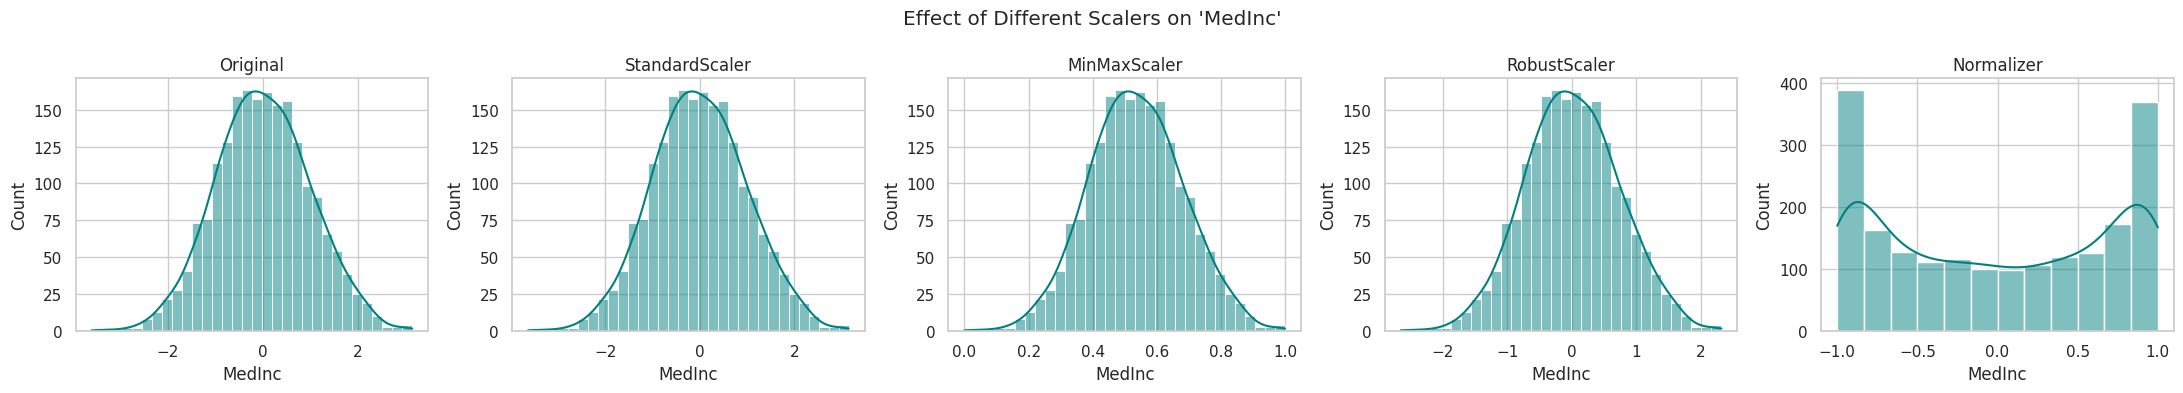

In [ ]:
housing_num = housing.select_dtypes(include=np.number).dropna()
sample_cols = housing_num.columns[:2]   # take 2 numeric columns to compare visually

scalers = {
    "Original":        housing_num[sample_cols],
    "StandardScaler":  pd.DataFrame(StandardScaler().fit_transform(housing_num[sample_cols]), columns=sample_cols),
    "MinMaxScaler":    pd.DataFrame(MinMaxScaler().fit_transform(housing_num[sample_cols]),   columns=sample_cols),
    "RobustScaler":    pd.DataFrame(RobustScaler().fit_transform(housing_num[sample_cols]),   columns=sample_cols),
    "Normalizer":      pd.DataFrame(Normalizer().fit_transform(housing_num[sample_cols]),     columns=sample_cols),
}

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, data) in zip(axes, scalers.items()):
    sns.histplot(data[sample_cols[0]], ax=ax, kde=True, color="teal")
    ax.set_title(name)
plt.suptitle(f"Effect of Different Scalers on '{sample_cols[0]}'")
plt.tight_layout()
plt.show()

---
# 1️4️. Encoding Categorical Data

ML algorithms need **numbers**, not text — encoding converts categories into numeric form.

In [ ]:
demo_enc = titanic[["sex", "embarked", "pclass"]].dropna().copy()

# 1. Label Encoding — assigns each category an integer (0, 1, 2, ...)
le = LabelEncoder()
demo_enc["sex_label"] = le.fit_transform(demo_enc["sex"])

# 2. One-Hot Encoding — creates a separate 0/1 column for every category
one_hot = pd.get_dummies(demo_enc["embarked"], prefix="embarked")

# 3. Ordinal Encoding — like Label Encoding, but you CONTROL the order
#    (pclass 1 = best, 3 = worst, so we keep that natural order)
ordinal = OrdinalEncoder(categories=[[1, 2, 3]])
demo_enc["pclass_ordinal"] = ordinal.fit_transform(demo_enc[["pclass"]])

result = pd.concat([demo_enc[["sex", "sex_label"]], one_hot,
                     demo_enc[["pclass", "pclass_ordinal"]]], axis=1)
result.head()

,sex,sex_label,embarked_C,embarked_Q,embarked_S,pclass,pclass_ordinal
0,male,1,False,False,True,3,2.0
1,female,0,True,False,False,1,0.0
2,female,0,False,False,True,3,2.0
3,female,0,False,False,True,1,0.0
4,male,1,False,False,True,3,2.0


| Method | How it works | Use for |
|---|---|---|
| **Label Encoding** | Category → single integer | Ordinal data, or tree-based models |
| **One-Hot Encoding** | Category → multiple 0/1 columns | Nominal data (no order), linear models |
| **Ordinal Encoding** | Category → integer, in a *meaningful* order | Data with a clear rank (Low/Medium/High) |
| **Binary Encoding** *(intro)* | Category → binary code split across fewer columns | High-cardinality categorical columns |

>  **Common mistake:** Using plain **Label Encoding** on a *nominal* column like `embarked`
> ('C', 'Q', 'S'). It implies a false order (C < Q < S) that many algorithms will
> misinterpret as meaningful — use **One-Hot Encoding** instead for nominal data.

---
# 1️5️. Data Visualization — The Complete Toolkit

This is the **biggest and most important section**. For each plot type you'll see:
**Purpose → When to use → Code → Interpretation**. We'll mix Titanic, Iris, and Tips
datasets to show each plot on the data it suits best.

###  1. Histogram
**Purpose:** Shows the *distribution* (shape/spread) of a single numerical variable.
**When to use:** Understanding how one numeric column is spread out — skewed? normal? bimodal?

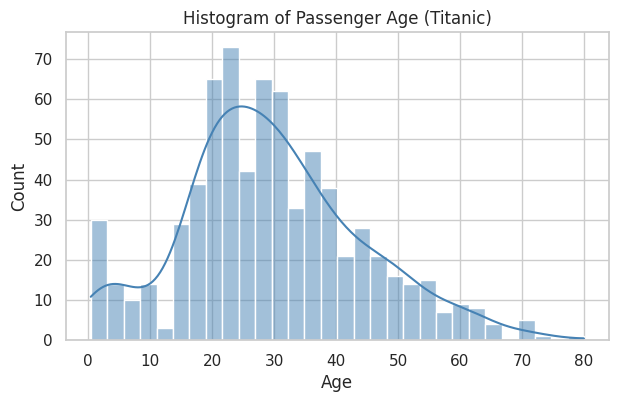

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(titanic["age"], bins=30, kde=True, color="steelblue")
plt.title("Histogram of Passenger Age (Titanic)")
plt.xlabel("Age")
plt.show()

###  2. Countplot
**Purpose:** Shows the *frequency* of each category in a categorical column.
**When to use:** Comparing counts across categories (class imbalance checks).

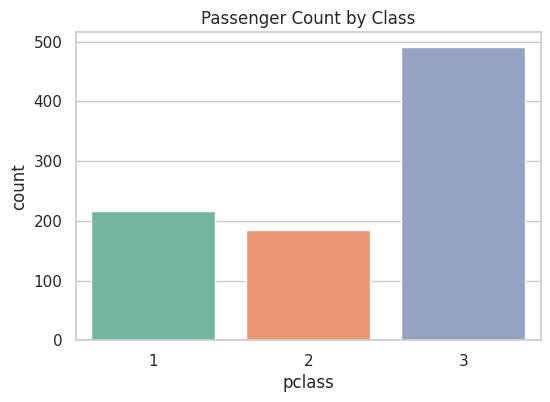

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x="pclass", data=titanic, hue="pclass", palette="Set2", legend=False)
plt.title("Passenger Count by Class")
plt.show()

###  3. Barplot
**Purpose:** Shows the *average* (or another statistic) of a numeric variable across categories.
**When to use:** Comparing a summary statistic (like mean survival rate) between groups.

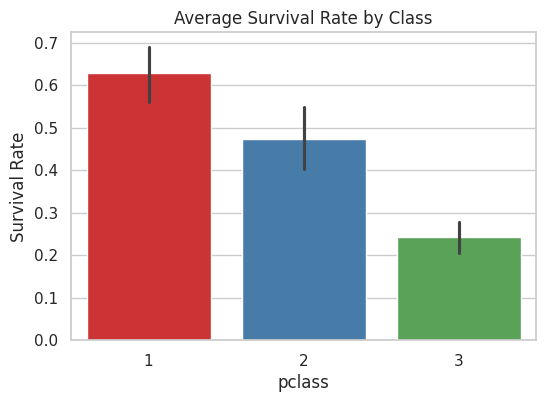

In [ ]:
plt.figure(figsize=(6, 4))
sns.barplot(x="pclass", y="survived", data=titanic, hue="pclass", palette="Set1", legend=False)
plt.title("Average Survival Rate by Class")
plt.ylabel("Survival Rate")
plt.show()

###  4. Boxplot
**Purpose:** Shows median, quartiles, and outliers of a numeric variable — optionally split by category.
**When to use:** Comparing distributions & spotting outliers across groups.

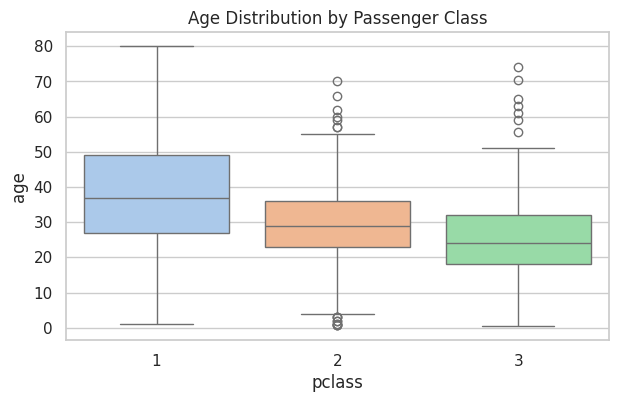

In [ ]:
plt.figure(figsize=(7, 4))
sns.boxplot(x="pclass", y="age", data=titanic, hue="pclass", palette="pastel", legend=False)
plt.title("Age Distribution by Passenger Class")
plt.show()

###  5. Violin Plot
**Purpose:** Combines a boxplot with a KDE (density) curve, showing the full *shape* of the distribution.
**When to use:** When you want more distributional detail than a boxplot alone gives.

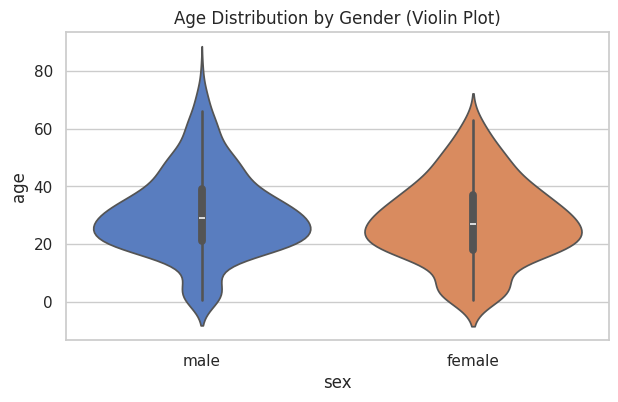

In [ ]:
plt.figure(figsize=(7, 4))
sns.violinplot(x="sex", y="age", data=titanic, hue="sex", palette="muted", legend=False)
plt.title("Age Distribution by Gender (Violin Plot)")
plt.show()

###  6. Scatter Plot
**Purpose:** Shows the relationship between **two** numerical variables.
**When to use:** Spotting correlation, trends, or clusters between two continuous variables.

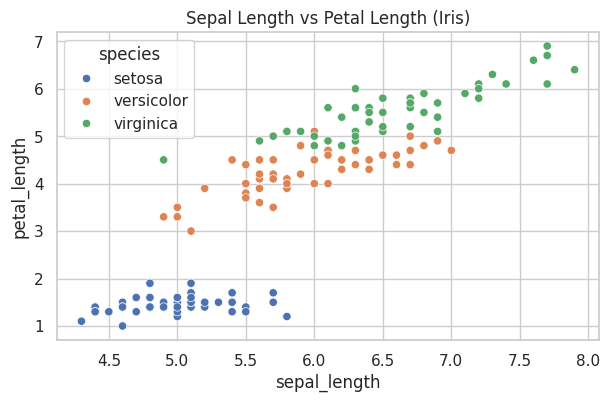

In [ ]:
plt.figure(figsize=(7, 4))
sns.scatterplot(x="sepal_length", y="petal_length", hue="species", data=iris, palette="deep")
plt.title("Sepal Length vs Petal Length (Iris)")
plt.show()

###  7. Pairplot
**Purpose:** Plots every pair of numerical columns against each other in one grid, with
histograms on the diagonal.
**When to use:** A fast, complete first look at relationships between *all* numeric features.

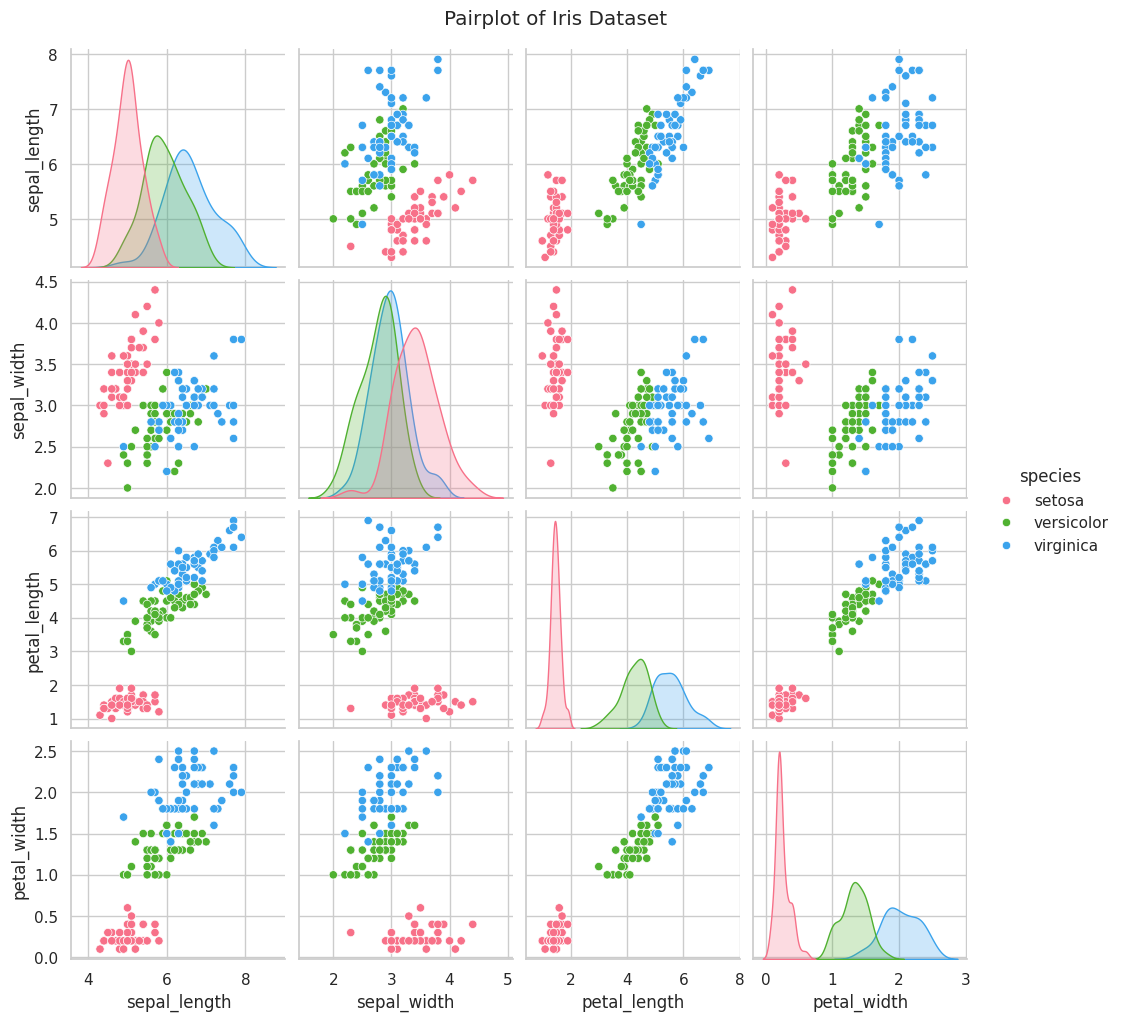

In [ ]:
sns.pairplot(iris, hue="species", palette="husl", diag_kind="kde")
plt.suptitle("Pairplot of Iris Dataset", y=1.02)
plt.show()

###  8. Heatmap
**Purpose:** Visualizes a matrix of values (commonly correlation) using color intensity.
**When to use:** Spotting strong positive/negative relationships across many variables at once (already used in Section 11!).

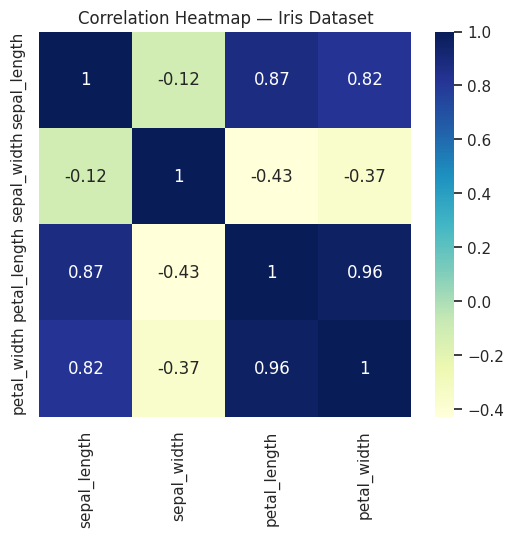

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(iris.drop(columns="species").corr(), annot=True, cmap="YlGnBu")
plt.title("Correlation Heatmap — Iris Dataset")
plt.show()

---
#  Mini Guided EDA Project — Tips Dataset



In [ ]:
# STEP 1 (example, already solved): First look at the data
print(tips.shape)
tips.head()

(244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [ ]:
# STEP 2: Check for missing values
# TODO: use isnull().sum() on the tips dataset
tips.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [ ]:
# STEP 3: Check for duplicate rows
# TODO: use duplicated().sum()
tips.duplicated().sum()

np.int64(1)

In [ ]:
# STEP 4: Get summary statistics
# TODO: use describe()
tips.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


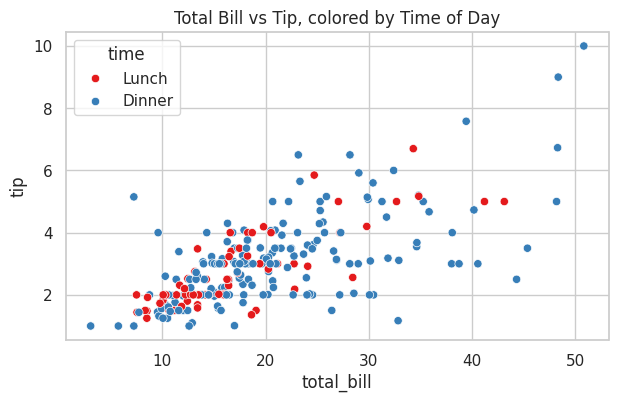

In [ ]:
# STEP 5: Visualize the relationship between total_bill and tip
# TODO: create a scatter plot, colored by 'time'
plt.figure(figsize=(7, 4))
sns.scatterplot(x="total_bill", y="tip", hue="time", data=tips, palette="Set1")
plt.title("Total Bill vs Tip, colored by Time of Day")
plt.show()

# Mini Assignment — Full EDA on the Penguins Dataset

**Load Dataset**

In [2]:

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Penguins dataset
df = sns.load_dataset("penguins")



,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


**Display Rows**

In [3]:
#Display the first five rows
df.head()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [4]:
# Display last five rows
display(df.tail())


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,Male


In [5]:
# Check number of rows and columns
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset shape: (344, 7)
Number of rows: 344
Number of columns: 7


In [6]:
# Display column names
print("\nColumn names:")
print(df.columns.tolist())



Column names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


In [7]:
# Dataset information
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [8]:
# Statistical summary
display(df.describe())

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


**missing values in each column**

In [9]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values)


Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


In [10]:
# Total missing values in the dataset
print("\nTotal missing values:", df.isnull().sum().sum())



Total missing values: 19


In [11]:
# Percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing values percentage:")
print(missing_percentage.round(2))



Missing values percentage:
species              0.00
island               0.00
bill_length_mm       0.58
bill_depth_mm        0.58
flipper_length_mm    0.58
body_mass_g          0.58
sex                  3.20
dtype: float64


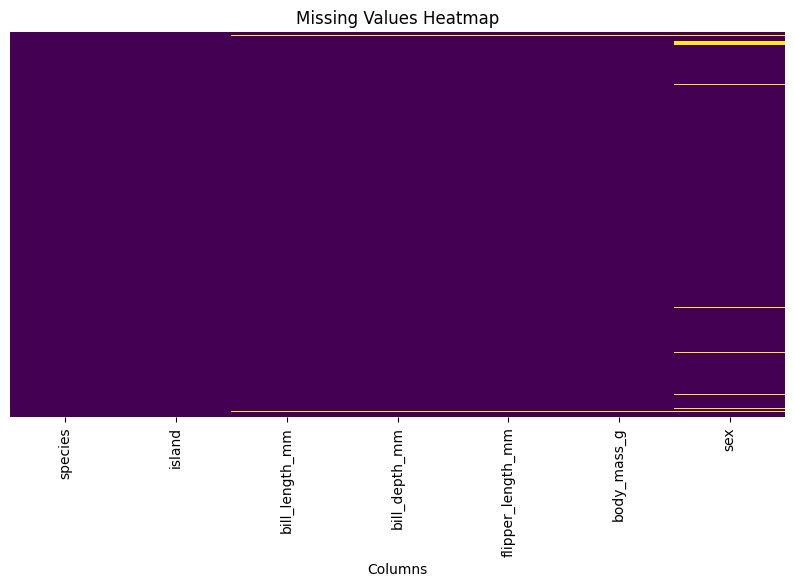

In [12]:
# Visualize missing values
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values Heatmap")
plt.xlabel("Columns")
plt.show()

**Find duplicate rows**

In [13]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [14]:
# Display duplicate rows, if any
duplicates = df[df.duplicated()]
display(duplicates)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex


**Correlation matrix and heatmap**

In [15]:
# Select numeric columns
numeric_df = df.select_dtypes(include="number")


In [16]:
# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000000,-0.235053,0.656181,0.595110
bill_depth_mm,-0.235053,1.000000,-0.583851,-0.471916
flipper_length_mm,0.656181,-0.583851,1.000000,0.871202
body_mass_g,0.595110,-0.471916,0.871202,1.000000


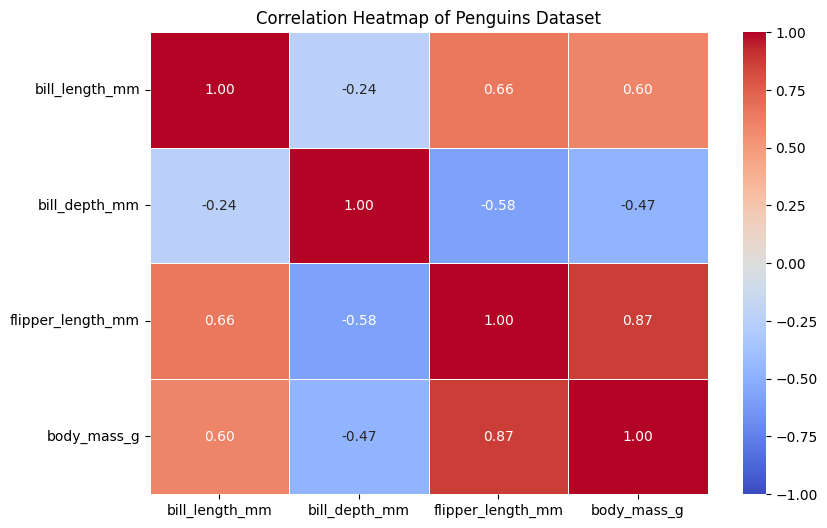

In [17]:
# Plot correlation heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Penguins Dataset")
plt.show()

**Boxplot of bill length grouped by species**

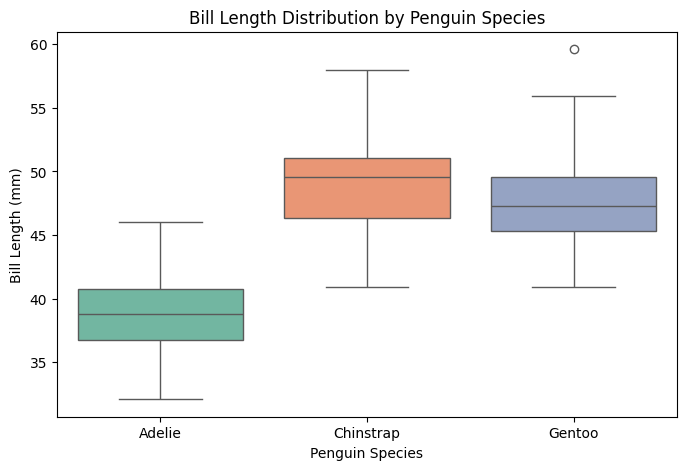

In [18]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="species",
    y="bill_length_mm",
    hue="species",
    legend=False,
    palette="Set2"
)

plt.title("Bill Length Distribution by Penguin Species")
plt.xlabel("Penguin Species")
plt.ylabel("Bill Length (mm)")
plt.show()



**Pairplot colored by species**




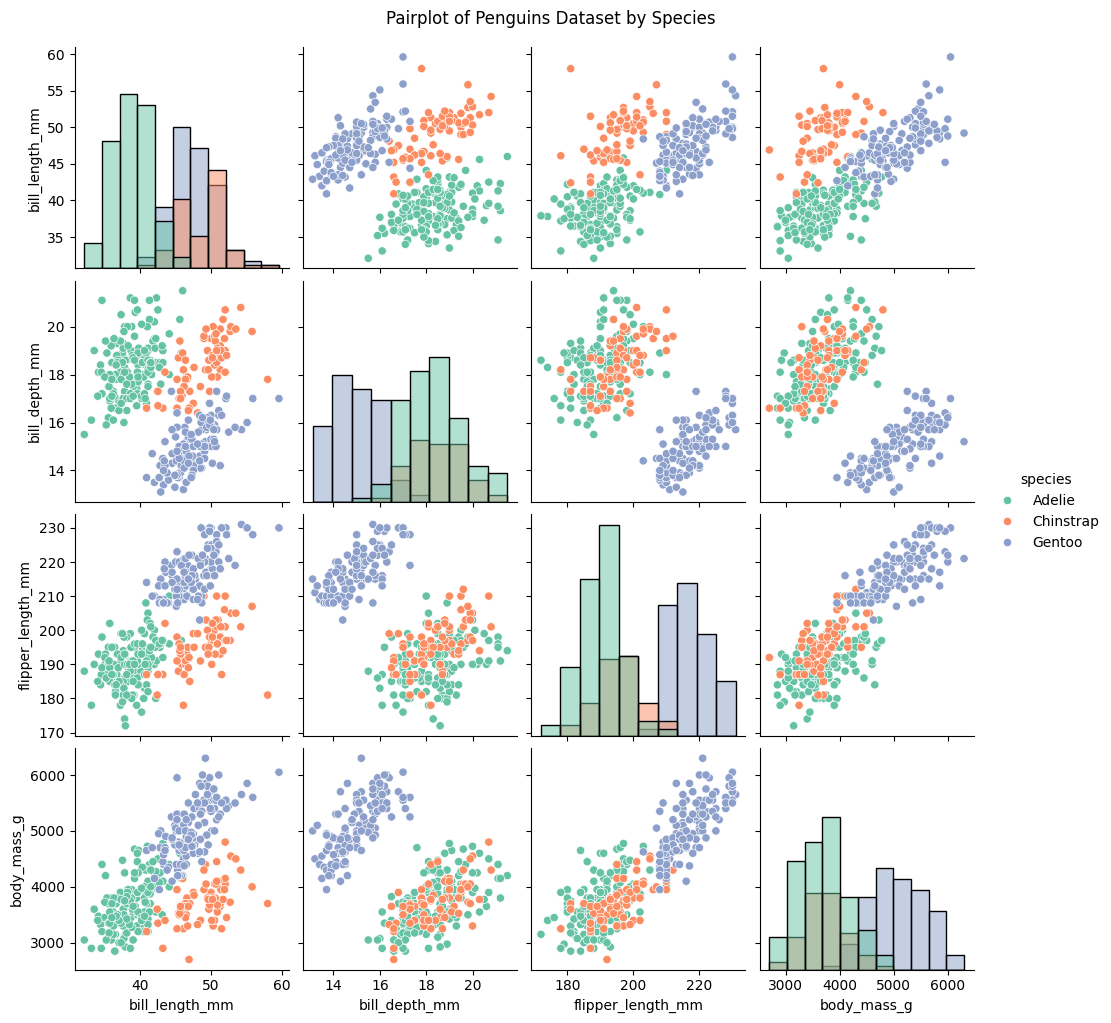

In [19]:

sns.pairplot(
    df,
    hue="species",
    vars=[
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g"
    ],
    diag_kind="hist",
    palette="Set2"
)

plt.suptitle("Pairplot of Penguins Dataset by Species", y=1.02)
plt.show()


**Clean the Dataset**

In [20]:
# Make a copy of the original dataset
clean_df = df.copy()


In [21]:
# Remove duplicate rows
clean_df = clean_df.drop_duplicates()


In [22]:
# Remove rows containing missing values
clean_df = clean_df.dropna()


In [23]:
# Reset the index
clean_df = clean_df.reset_index(drop=True)


In [24]:
# Display cleaned dataset
display(clean_df.head())


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


In [25]:
# Verify cleaning
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", clean_df.shape)

print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(clean_df.duplicated().sum())

Original dataset shape: (344, 7)
Cleaned dataset shape: (333, 7)

Missing values after cleaning:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

Duplicate rows after cleaning:
0


In [26]:
# Confirm the dataset is fully cleaned
print("\nIs dataset free from missing values?",
      not clean_df.isnull().any().any())

print("Is dataset free from duplicates?",
      not clean_df.duplicated().any())



Is dataset free from missing values? True
Is dataset free from duplicates? True


**Save the cleaned dataset**

In [27]:

# Save the cleaned dataset as a CSV file
clean_df.to_csv("penguins_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


**Final EDA summary**

In [28]:

print("========== PENGUINS DATASET EDA SUMMARY ==========")

print(f"Original rows: {df.shape[0]}")
print(f"Original columns: {df.shape[1]}")

print(f"\nTotal missing values: {df.isnull().sum().sum()}")
print("\nMissing values per column:")
print(df.isnull().sum())

print(f"\nDuplicate rows: {df.duplicated().sum()}")

print("\nSpecies counts:")
print(df["species"].value_counts())

print(f"\nRows after cleaning: {clean_df.shape[0]}")
print(f"Columns after cleaning: {clean_df.shape[1]}")

print(f"\nMissing values remaining: {clean_df.isnull().sum().sum()}")
print(f"Duplicate rows remaining: {clean_df.duplicated().sum()}")

print("\nEDA completed successfully!")


========== PENGUINS DATASET EDA SUMMARY ==========
Original rows: 344
Original columns: 7

Total missing values: 19

Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Duplicate rows: 0

Species counts:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Rows after cleaning: 333
Columns after cleaning: 7

Missing values remaining: 0
Duplicate rows remaining: 0

EDA completed successfully!
